# Stock Market Volatility Prediction (NIFTY 50)

Predict whether NIFTY 50 will be in a **high volatility** period over the next 10 trading days (annualized volatility above 18%).

Volatility is the standard measure of market risk. High volatility periods tend to cluster (a turbulent market usually stays turbulent for a while), so they can be predicted from today's data.

Models: Linear Regression, Logistic Regression, KNN, Decision Tree, MLP, Random Forest.

## 1. Data Loading

Daily data from Yahoo Finance, 2010 onwards: NIFTY 50 (main), S&P 500, India VIX, USD/INR, crude oil.

In [1]:
import os
import shutil
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

raw_dir = 'data/raw'
processed_dir = 'data/processed'
os.makedirs(raw_dir, exist_ok=True)
os.makedirs(processed_dir, exist_ok=True)

tickers = {
    'nifty': '^NSEI',
    'sp500': '^GSPC',
    'india_vix': '^INDIAVIX',
    'usd_inr': 'INR=X',
    'crude_oil': 'CL=F',
}
start_date = '2010-01-01'
end_date = '2026-10-31'

# download each dataset once and save it as csv, after that read it from the csv
data = {}
for name, ticker in tickers.items():
    path = os.path.join(raw_dir, name + '.csv')
    if not os.path.exists(path):
        temp = yf.download(ticker, start=start_date, end=end_date, auto_adjust=False, progress=False)
        temp.columns = temp.columns.get_level_values(0)
        temp.to_csv(path)
    data[name] = pd.read_csv(path, index_col='Date', parse_dates=True)
    print(name, len(data[name]), 'rows')

df = data['nifty'][['Open', 'High', 'Low', 'Close', 'Volume']].copy()
df.head()

nifty 4133 rows
sp500 4233 rows
india_vix 4132 rows
usd_inr 4381 rows
crude_oil 4233 rows


,Open,High,Low,Close,Volume
Date,,,,,
2010-01-04,5200.899902,5238.450195,5167.100098,5232.200195,0
2010-01-05,5277.149902,5288.350098,5242.399902,5277.899902,0
2010-01-06,5278.149902,5310.850098,5260.049805,5281.799805,0
2010-01-07,5281.799805,5302.549805,5244.750000,5263.100098,0
2010-01-08,5264.250000,5276.750000,5234.700195,5244.750000,0


### Data overview

In [2]:
print('Shape:', df.shape)
print('Date range:', df.index.min().date(), 'to', df.index.max().date())
print()
print(df.dtypes)
print()
df.info()

Shape: (4133, 5)
Date range: 2010-01-04 to 2026-10-30

Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

<class 'pandas.DataFrame'>
DatetimeIndex: 4133 entries, 2010-01-04 to 2026-10-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    4133 non-null   float64
 1   High    4133 non-null   float64
 2   Low     4133 non-null   float64
 3   Close   4133 non-null   float64
 4   Volume  4133 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 193.7 KB


In [3]:
# check every dataset for missing values, zero prices and duplicate dates
for name in data:
    temp = data[name]
    print(name)
    print('   rows:', len(temp), ' from', temp.index.min().date(), 'to', temp.index.max().date())
    print('   missing close:', temp['Close'].isnull().sum(), ' zero close:', (temp['Close'] == 0).sum(),
          ' duplicate dates:', temp.index.duplicated().sum())

nifty
   rows: 4133  from 2010-01-04 to 2026-10-30
   missing close: 0  zero close: 0  duplicate dates: 0
sp500
   rows: 4233  from 2010-01-04 to 2026-10-30
   missing close: 0  zero close: 0  duplicate dates: 0
india_vix
   rows: 4132  from 2010-01-04 to 2026-10-30
   missing close: 0  zero close: 0  duplicate dates: 0
usd_inr
   rows: 4381  from 2010-01-01 to 2026-10-30
   missing close: 0  zero close: 0  duplicate dates: 0
crude_oil
   rows: 4233  from 2010-01-04 to 2026-10-30
   missing close: 0  zero close: 0  duplicate dates: 0


## 2. Data Preprocessing

In [4]:
df_clean = df[~df.index.duplicated(keep='first')].dropna().sort_index()
df_clean = df_clean[df_clean['Close'] > 0]
print('Rows after removing duplicates and missing:', len(df_clean))

close = df_clean['Close']

df_clean['return_1d'] = close.pct_change()
df_clean['momentum_10'] = close / close.shift(10) - 1
df_clean['volatility_10'] = df_clean['return_1d'].rolling(10).std() * np.sqrt(252)
df_clean['volatility_20'] = df_clean['return_1d'].rolling(20).std() * np.sqrt(252)
df_clean['ma_ratio'] = close.rolling(20).mean() / close.rolling(50).mean()
df_clean['day_range'] = (df_clean['High'] - df_clean['Low']) / close
df_clean['drawdown'] = close / close.rolling(252, min_periods=1).max() - 1

change = close.diff()
avg_gain = change.clip(lower=0).rolling(14).mean()
avg_loss = (-change.clip(upper=0)).rolling(14).mean()
df_clean['rsi_14'] = 100 - 100 / (1 + avg_gain / avg_loss)

ema12 = close.ewm(span=12, adjust=False).mean()
ema26 = close.ewm(span=26, adjust=False).mean()
df_clean['macd'] = (ema12 - ema26) / close

feature_cols = ['return_1d', 'momentum_10', 'volatility_10', 'volatility_20', 'ma_ratio',
                'day_range', 'drawdown', 'rsi_14', 'macd']

Rows after removing duplicates and missing: 4133


In [5]:
sp500 = data['sp500']['Close']
vix = data['india_vix']['Close']
inr = data['usd_inr']['Close']
oil = data['crude_oil']['Close']
oil = oil[oil > 0]   # crude oil went below zero once in April 2020

# the US market, USD/INR and crude oil close after the Indian market,
# so for each Indian day we use their previous day's value (shift 1)
df_clean['sp500_return'] = sp500.pct_change().shift(1).reindex(df_clean.index, method='ffill')
df_clean['nifty_sp500_corr'] = df_clean['return_1d'].rolling(60).corr(df_clean['sp500_return'])

vix = vix.reindex(df_clean.index).ffill(limit=3)
df_clean['india_vix'] = vix
df_clean['vix_change_5'] = vix / vix.shift(5) - 1
df_clean['vix_ratio'] = vix / vix.rolling(252, min_periods=60).mean()   # VIX compared with its 1 year average

inr = inr.shift(1).reindex(df_clean.index, method='ffill')
df_clean['usd_inr_change_5'] = inr / inr.shift(5) - 1

df_clean['crude_return'] = oil.pct_change().shift(1).reindex(df_clean.index, method='ffill').clip(-0.3, 0.3)

feature_cols += ['sp500_return', 'nifty_sp500_corr', 'india_vix', 'vix_change_5', 'vix_ratio',
                 'usd_inr_change_5', 'crude_return']
print('Features:', len(feature_cols))
print(feature_cols)

Features: 16
['return_1d', 'momentum_10', 'volatility_10', 'volatility_20', 'ma_ratio', 'day_range', 'drawdown', 'rsi_14', 'macd', 'sp500_return', 'nifty_sp500_corr', 'india_vix', 'vix_change_5', 'vix_ratio', 'usd_inr_change_5', 'crude_return']


### Target

`future_vol` = standard deviation of the next 10 daily returns, annualized ($\times\sqrt{252}$). Only future days are used, today's return is not included.

target = 1 (high volatility ahead) if `future_vol` > 18%, else 0. 18% is roughly the top 25% of days in the training period.

`future_vol` itself (a number) is kept as the regression target.

In [6]:
horizon = 10
vol_threshold = 0.18

# put the returns of the next 10 days side by side, one column per day
future_returns = pd.DataFrame(index=df_clean.index)
for k in range(1, horizon + 1):
    future_returns[k] = df_clean['return_1d'].shift(-k)

# volatility of the NEXT 10 days (yearly scale)
df_clean['future_vol'] = future_returns.std(axis=1, skipna=False) * np.sqrt(252)
df_clean['target'] = (df_clean['future_vol'] > vol_threshold).astype(int)

print('Missing values before dropping:')
print(df_clean[feature_cols + ['future_vol']].isnull().sum())

# first rows have no history and last 10 rows have no future, so they are dropped
df_clean = df_clean.dropna(subset=feature_cols + ['future_vol'])
print()
print('Rows left:', len(df_clean))
print(df_clean['target'].value_counts())
print('High volatility days (%):', round(df_clean['target'].mean() * 100, 1))

Missing values before dropping:
return_1d            1
momentum_10         10
volatility_10       10
volatility_20       20
ma_ratio            49
day_range            0
drawdown             0
rsi_14              14
macd                 0
sp500_return         2
nifty_sp500_corr    61
india_vix            0
vix_change_5         5
vix_ratio           59
usd_inr_change_5     5
crude_return         2
future_vol          10
dtype: int64

Rows left: 4062
target
0    3231
1     831
Name: count, dtype: int64
High volatility days (%): 20.5


### Market regime (categorical)

In [7]:
vol_cutoff = df_clean['volatility_20'].quantile(0.80)

def get_regime(row):
    if row['volatility_20'] > vol_cutoff:
        return 'High Volatility'
    if row['ma_ratio'] > 1.01:
        return 'Bull'
    if row['ma_ratio'] < 0.99:
        return 'Bear'
    return 'Sideways'

df_clean['regime'] = df_clean.apply(get_regime, axis=1)
regime_order = ['Bull', 'Sideways', 'Bear', 'High Volatility']

regime_table = pd.DataFrame({
    'Days': df_clean['regime'].value_counts().reindex(regime_order),
    'High vol %': (df_clean.groupby('regime')['target'].mean() * 100).reindex(regime_order).round(1)
})
print(regime_table)

pd.get_dummies(df_clean['regime'], prefix='regime').head()

                 Days  High vol %
regime                           
Bull             1707        11.7
Sideways          976        15.7
Bear              566        17.7
High Volatility   813        46.6


,regime_Bear,regime_Bull,regime_High Volatility,regime_Sideways
Date,,,,
2010-04-06,False,True,False,False
2010-04-07,False,True,False,False
2010-04-08,False,True,False,False
2010-04-09,False,True,False,False
2010-04-12,False,True,False,False


In [8]:
# save the cleaned data and zip all the data files
df_clean.to_csv('data/processed/cleaned_nifty_data.csv')
shutil.make_archive('datasets_used', 'zip', 'data')
print('Saved data/processed/cleaned_nifty_data.csv')
print('Created datasets_used.zip')

Saved data/processed/cleaned_nifty_data.csv
Created datasets_used.zip


## 3. Exploratory Data Analysis

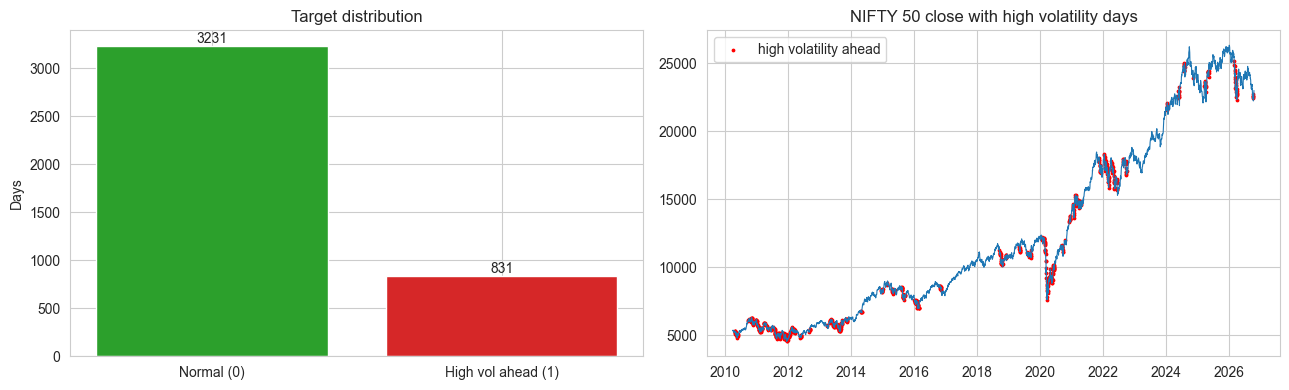

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = df_clean['target'].value_counts().sort_index()
axes[0].bar(['Normal (0)', 'High vol ahead (1)'], counts.values, color=['tab:green', 'tab:red'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom')
axes[0].set_title('Target distribution')
axes[0].set_ylabel('Days')

axes[1].plot(df_clean.index, df_clean['Close'], linewidth=0.8)
high = df_clean[df_clean['target'] == 1]
axes[1].scatter(high.index, high['Close'], s=3, color='red', label='high volatility ahead')
axes[1].set_title('NIFTY 50 close with high volatility days')
axes[1].legend()
plt.tight_layout()
plt.show()

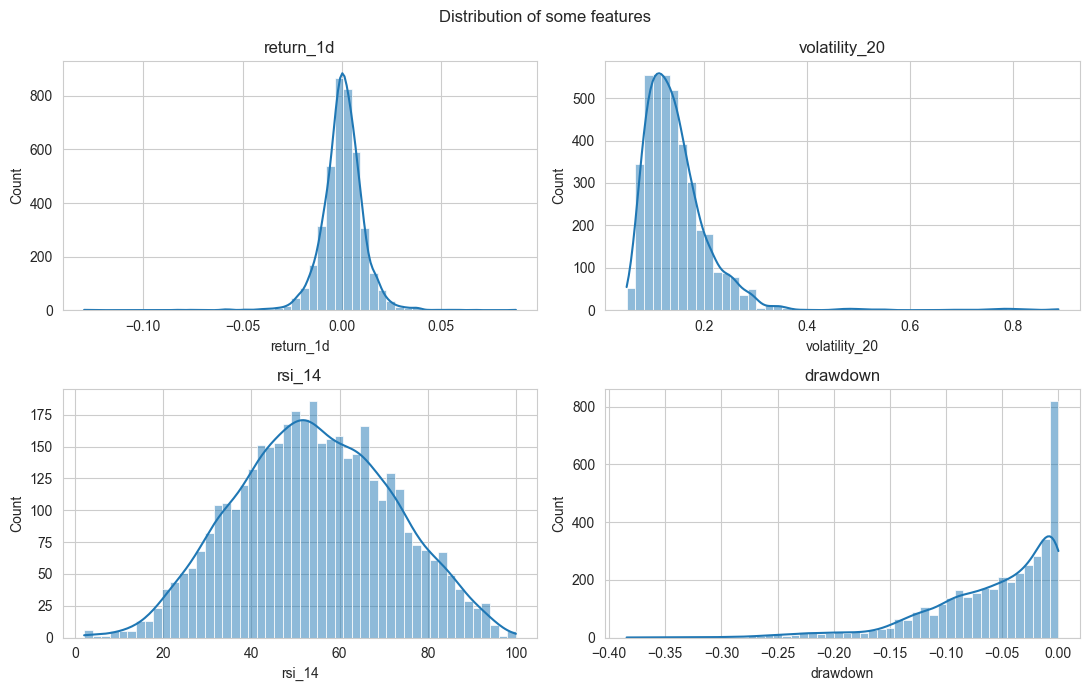

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ['return_1d', 'volatility_20', 'rsi_14', 'drawdown']):
    sns.histplot(df_clean[col], bins=50, kde=True, ax=ax)
    ax.set_title(col)
plt.suptitle('Distribution of some features')
plt.tight_layout()
plt.show()

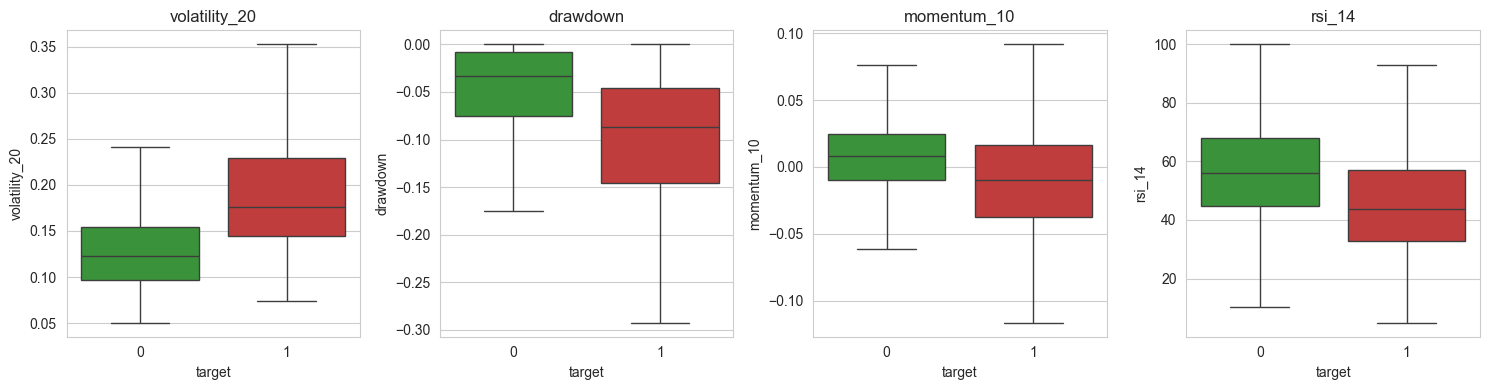

target,0,1
return_1d,0.0010,-0.0017
momentum_10,0.0079,-0.0105
volatility_10,0.1283,0.2032
volatility_20,0.1319,0.2055
ma_ratio,1.0086,0.9946
day_range,0.0104,0.0168
drawdown,-0.0462,-0.1039
rsi_14,56.2997,46.2500
macd,0.0042,-0.0054
sp500_return,0.0007,-0.0003


In [11]:
box_cols = ['volatility_20', 'drawdown', 'momentum_10', 'rsi_14']
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, box_cols):
    sns.boxplot(data=df_clean, x='target', y=col, ax=ax, showfliers=False, palette=['tab:green', 'tab:red'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

df_clean.groupby('target')[feature_cols].mean().T.round(4)

### Correlations

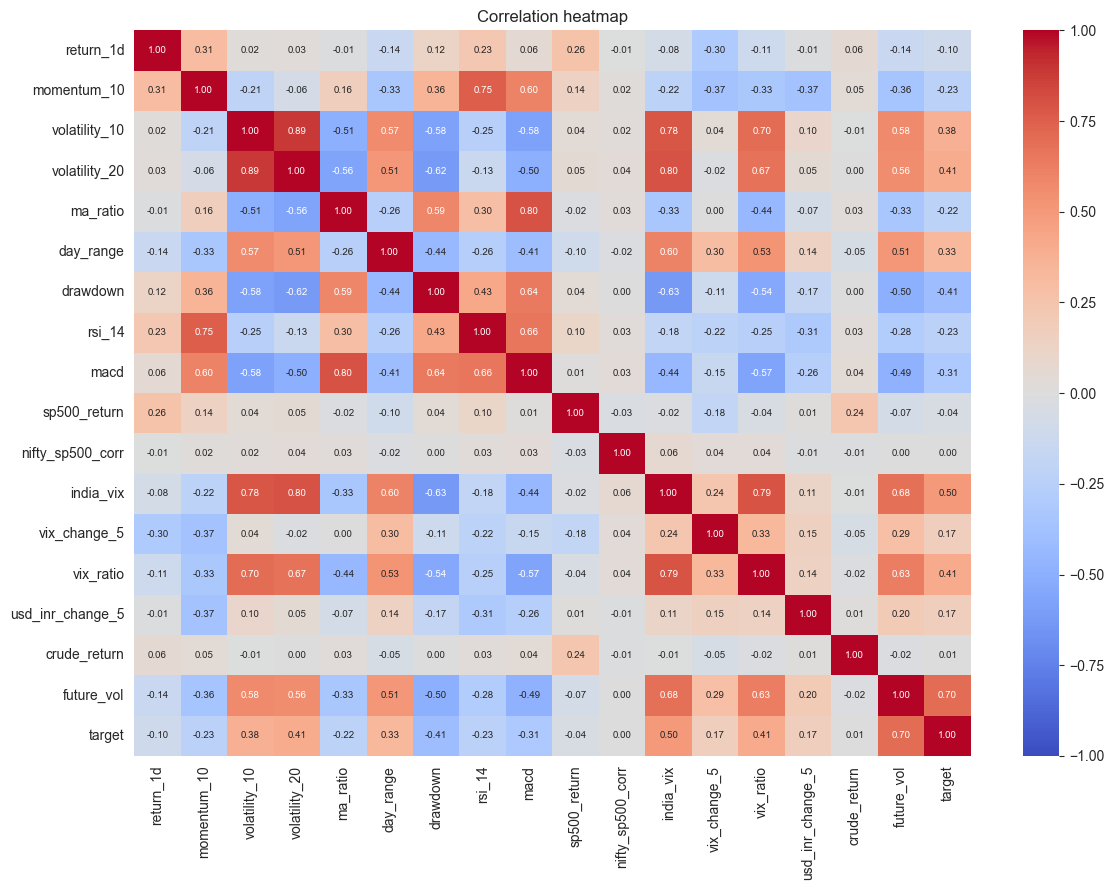

Correlation with future_vol:
drawdown           -0.496
macd               -0.491
momentum_10        -0.357
ma_ratio           -0.335
rsi_14             -0.282
return_1d          -0.143
sp500_return       -0.071
crude_return       -0.023
nifty_sp500_corr    0.003
usd_inr_change_5    0.196
vix_change_5        0.286
day_range           0.514
volatility_20       0.558
volatility_10       0.576
vix_ratio           0.631
india_vix           0.680
Name: future_vol, dtype: float64


In [12]:
corr = df_clean[feature_cols + ['future_vol', 'target']].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

print('Correlation with future_vol:')
print(corr['future_vol'].drop(['future_vol', 'target']).sort_values().round(3))

## 4. Train / Test Split

Time based split (no shuffling): first 75% train, last 25% test, with a 10 day gap. Scaler is fitted on train only.

In [13]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X = df_clean[feature_cols]
y = df_clean['target']
y_reg = df_clean['future_vol']

# first 75% of days for training, last 25% for testing, 10 day gap in between
split = int(len(df_clean) * 0.75)
X_train = X.iloc[:split - horizon]
y_train = y.iloc[:split - horizon]
yreg_train = y_reg.iloc[:split - horizon]
X_test = X.iloc[split:]
y_test = y.iloc[split:]
yreg_test = y_reg.iloc[split:]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Train:', X_train.index.min().date(), 'to', X_train.index.max().date(), '-', len(X_train), 'days')
print('Test :', X_test.index.min().date(), 'to', X_test.index.max().date(), '-', len(X_test), 'days')
print('High vol days in train:', y_train.sum())
print('High vol days in test :', y_test.sum())

Train: 2010-04-06 to 2022-08-18 - 3036 days
Test : 2022-09-05 to 2026-10-15 - 1016 days
High vol days in train: 743
High vol days in test : 86


In [14]:
# MinMax vs Standard scaling on two features
demo = X_train[['india_vix', 'rsi_14']]
print('Original values:')
print(demo.describe().loc[['mean', 'std', 'min', 'max']].round(3))

minmax = MinMaxScaler().fit_transform(demo)
print('\nMinMax scaling   -> min:', minmax.min(axis=0).round(3), ' max:', minmax.max(axis=0).round(3))

standard = StandardScaler().fit_transform(demo)
print('Standard scaling -> mean:', standard.mean(axis=0).round(3), ' std:', standard.std(axis=0).round(3))

Original values:
      india_vix  rsi_14
mean     18.746  54.592
std       6.276  17.461
min      10.450   4.867
max      83.610  99.582

MinMax scaling   -> min: [0. 0.]  max: [1. 1.]
Standard scaling -> mean: [-0.  0.]  std: [1. 1.]


### Feature selection

The training period is cut into 4 blocks (about 3 years each). In each block the AUC of every feature is calculated on its own:
- AUC above 0.5: higher values of the feature come before high volatility
- AUC below 0.5: lower values of the feature come before high volatility

A feature is kept only if it points the **same way in all 4 blocks**. A feature that flips direction between periods is mostly noise, and noise makes the models worse on new data. Only training data is used, and all models from here on (regression and classification) use the kept features.

In [15]:
from sklearn.metrics import roc_auc_score

# split the training data into 4 parts (about 3 years each)
part_size = len(X_train) // 4

model_cols = []
for col in feature_cols:
    aucs = []
    for i in range(4):
        start = i * part_size
        end = (i + 1) * part_size
        auc = roc_auc_score(y_train.iloc[start:end], X_train[col].iloc[start:end])
        aucs.append(round(auc, 3))
    # keep the feature only if it is on the same side of 0.5 in all 4 parts
    if min(aucs) > 0.5 or max(aucs) < 0.5:
        model_cols.append(col)
        print(col, aucs, 'keep')
    else:
        print(col, aucs, 'drop')

print('\nKept', len(model_cols), 'of', len(feature_cols), 'features')

# from here on only the kept features are used
X = X[model_cols]
X_train = X_train[model_cols]
X_test = X_test[model_cols]
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

return_1d [0.444, 0.424, 0.401, 0.404] keep
momentum_10 [0.412, 0.278, 0.165, 0.317] keep
volatility_10 [0.703, 0.724, 0.749, 0.702] keep


volatility_20 [0.767, 0.721, 0.782, 0.737] keep


ma_ratio [0.375, 0.325, 0.268, 0.347] keep
day_range [0.686, 0.699, 0.749, 0.709] keep
drawdown [0.251, 0.288, 0.194, 0.286] keep
rsi_14 [0.363, 0.227, 0.15, 0.302] keep
macd [0.322, 0.223, 0.158, 0.301] keep
sp500_return [0.478, 0.493, 0.46, 0.453] keep
nifty_sp500_corr [0.492, 0.359, 0.455, 0.623] drop


india_vix [0.827, 0.773, 0.892, 0.724] keep


vix_change_5 [0.535, 0.635, 0.691, 0.585] keep


vix_ratio [0.838, 0.814, 0.855, 0.729] keep
usd_inr_change_5 [0.576, 0.702, 0.541, 0.585] keep
crude_return [0.495, 0.504, 0.465, 0.481] drop

Kept 14 of 16 features


## 5. Linear Regression

Target: `future_vol`. Simple, multiple and polynomial regression, fitted with OLS:

$$\hat{\beta} = (X^T X)^{-1} X^T y$$

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_results = []

def reg_metrics(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    reg_results.append([name, mae, mse, rmse, r2])

# baseline: always predict the average of the training data
baseline = np.full(len(yreg_test), yreg_train.mean())
reg_metrics('Baseline (train mean)', yreg_test, baseline)

Feature used: india_vix
Equation: future_vol = -0.0167 + 0.0091 * india_vix


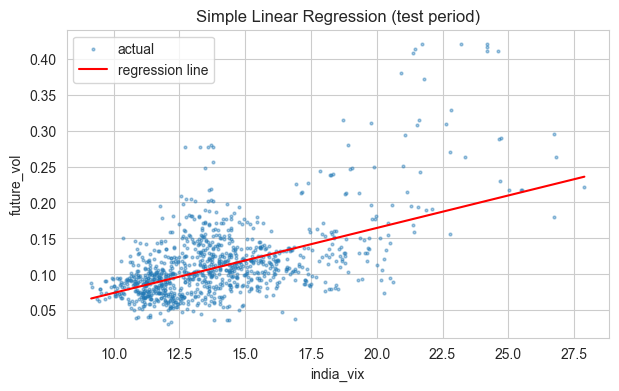

In [17]:
best_feature = corr.loc[model_cols, 'future_vol'].abs().idxmax()
print('Feature used:', best_feature)

slr = LinearRegression()
slr.fit(X_train[[best_feature]], yreg_train)
pred_slr = slr.predict(X_test[[best_feature]])
print('Equation: future_vol =', round(slr.intercept_, 4), '+', round(slr.coef_[0], 4), '*', best_feature)
reg_metrics('Simple Linear', yreg_test, pred_slr)

plt.figure(figsize=(7, 4))
plt.scatter(X_test[best_feature], yreg_test, s=4, alpha=0.4, label='actual')
xs = np.linspace(X_test[best_feature].min(), X_test[best_feature].max(), 100)
plt.plot(xs, slr.intercept_ + slr.coef_[0] * xs, color='red', label='regression line')
plt.xlabel(best_feature)
plt.ylabel('future_vol')
plt.title('Simple Linear Regression (test period)')
plt.legend()
plt.show()

In [18]:
mlr = LinearRegression()
mlr.fit(X_train_s, yreg_train)
pred_mlr = mlr.predict(X_test_s)
reg_metrics('Multiple Linear', yreg_test, pred_mlr)

# OLS by hand: beta = (X'X)^-1 X'y   (a column of 1s is added for the intercept)
X_ols = np.column_stack([np.ones(len(X_train_s)), X_train_s])
beta = np.linalg.inv(X_ols.T @ X_ols) @ X_ols.T @ yreg_train.values

coef_table = pd.DataFrame(index=['intercept'] + model_cols)
coef_table['sklearn'] = [mlr.intercept_] + list(mlr.coef_)
coef_table['OLS by hand'] = beta
coef_table.round(5)

,sklearn,OLS by hand
intercept,0.15308,0.15308
return_1d,-0.00460,-0.00460
momentum_10,-0.00480,-0.00480
volatility_10,-0.00530,-0.00530
volatility_20,0.01902,0.01902
ma_ratio,0.01310,0.01310
day_range,0.00695,0.00695
drawdown,0.00090,0.00090
rsi_14,0.00439,0.00439
macd,-0.02798,-0.02798


In [19]:
top4 = corr.loc[model_cols, 'future_vol'].abs().sort_values(ascending=False).index[:4].tolist()
print('Features used:', top4)

poly = PolynomialFeatures(degree=2, include_bias=False)
sc4 = StandardScaler().fit(X_train[top4])
P_train = poly.fit_transform(sc4.transform(X_train[top4]))
P_test = poly.transform(sc4.transform(X_test[top4]))
print('Number of terms after degree 2 expansion:', P_train.shape[1])

plr = LinearRegression()
plr.fit(P_train, yreg_train)
pred_plr = plr.predict(P_test)
reg_metrics('Polynomial (degree 2)', yreg_test, pred_plr)

Features used: ['india_vix', 'vix_ratio', 'volatility_10', 'volatility_20']
Number of terms after degree 2 expansion: 14


                           MAE      MSE     RMSE       R2
Model                                                    
Baseline (train mean)  0.05544  0.00433  0.06583 -0.48293
Simple Linear          0.02941  0.00193  0.04392  0.33984
Multiple Linear        0.03259  0.00221  0.04697  0.24520
Polynomial (degree 2)  0.03340  0.00218  0.04669  0.25387


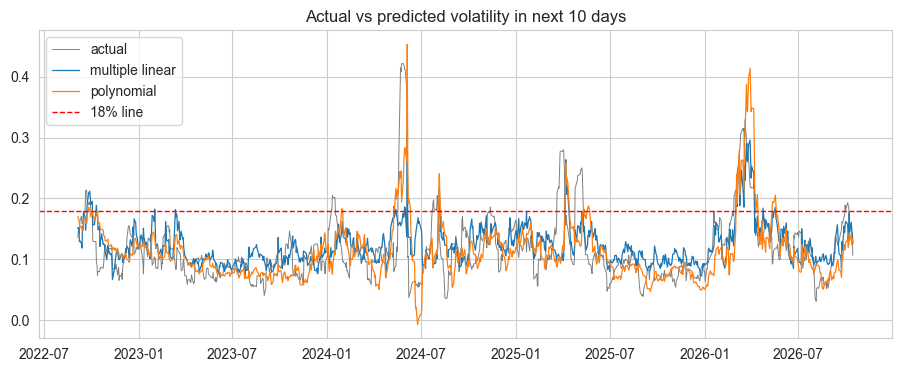

In [20]:
reg_df = pd.DataFrame(reg_results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']).set_index('Model')
print(reg_df.round(5))

plt.figure(figsize=(11, 4))
plt.plot(yreg_test.index, yreg_test, linewidth=0.7, label='actual', color='grey')
plt.plot(yreg_test.index, pred_mlr, linewidth=0.9, label='multiple linear')
plt.plot(yreg_test.index, pred_plr, linewidth=0.9, label='polynomial')
plt.axhline(vol_threshold, color='red', linestyle='--', linewidth=1, label='18% line')
plt.title('Actual vs predicted volatility in next 10 days')
plt.legend()
plt.show()

R² is positive: future volatility can partly be predicted, mostly from India VIX. The rest of the project treats the problem as yes/no classification (high volatility ahead or not).

## 6. Classification

High volatility days are the minority class, so `class_weight='balanced'` is used (oversampling for KNN and MLP).

The model settings (C, max_depth, n_neighbors, alpha, ...) were chosen by trying a few values with time series cross-validation on the training data only.

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import log_loss, confusion_matrix, roc_curve

results = []
preds = {}
probs = {}
models = {}

def evaluate(name, model, X_eval):
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]   # probability of high volatility

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    loss = log_loss(y_test, y_prob)

    print(name)
    print('Accuracy :', round(acc, 4))
    print('Precision:', round(prec, 4))
    print('Recall   :', round(rec, 4))
    print('F1       :', round(f1, 4))
    print('AUC      :', round(auc, 4))
    print('Log Loss :', round(loss, 4))

    results.append([name, acc, prec, rec, f1, auc, loss])
    preds[name] = y_pred
    probs[name] = y_prob
    models[name] = model

### Logistic Regression

$$P(y=1) = \frac{1}{1 + e^{-z}}$$

Logistic Regression
Accuracy : 0.8878
Precision: 0.36
Recall   : 0.4186
F1       : 0.3871
AUC      : 0.7598
Log Loss : 0.3625


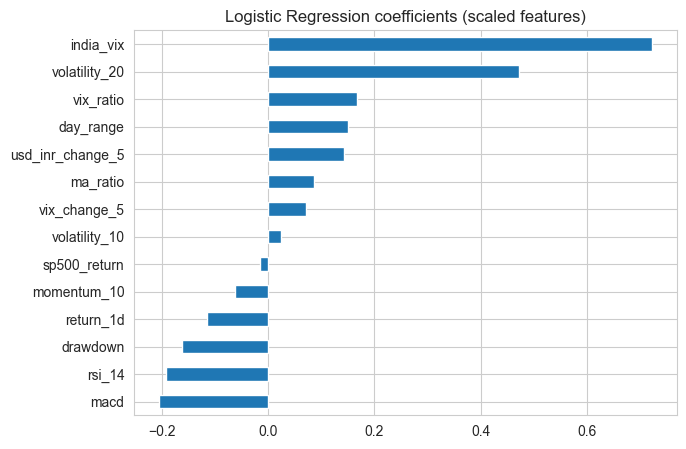

In [22]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(C=0.01, max_iter=1000, class_weight='balanced', random_state=42)
log_reg.fit(X_train_s, y_train)
evaluate('Logistic Regression', log_reg, X_test_s)

pd.Series(log_reg.coef_[0], index=model_cols).sort_values().plot(kind='barh', figsize=(7, 5))
plt.title('Logistic Regression coefficients (scaled features)')
plt.show()

### Decision Tree

$$Gini = 1 - \sum p_i^2$$

In [23]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)
evaluate('Decision Tree', tree, X_test)

Decision Tree
Accuracy : 0.8287
Precision: 0.2179
Recall   : 0.3953
F1       : 0.281
AUC      : 0.7505
Log Loss : 1.0298


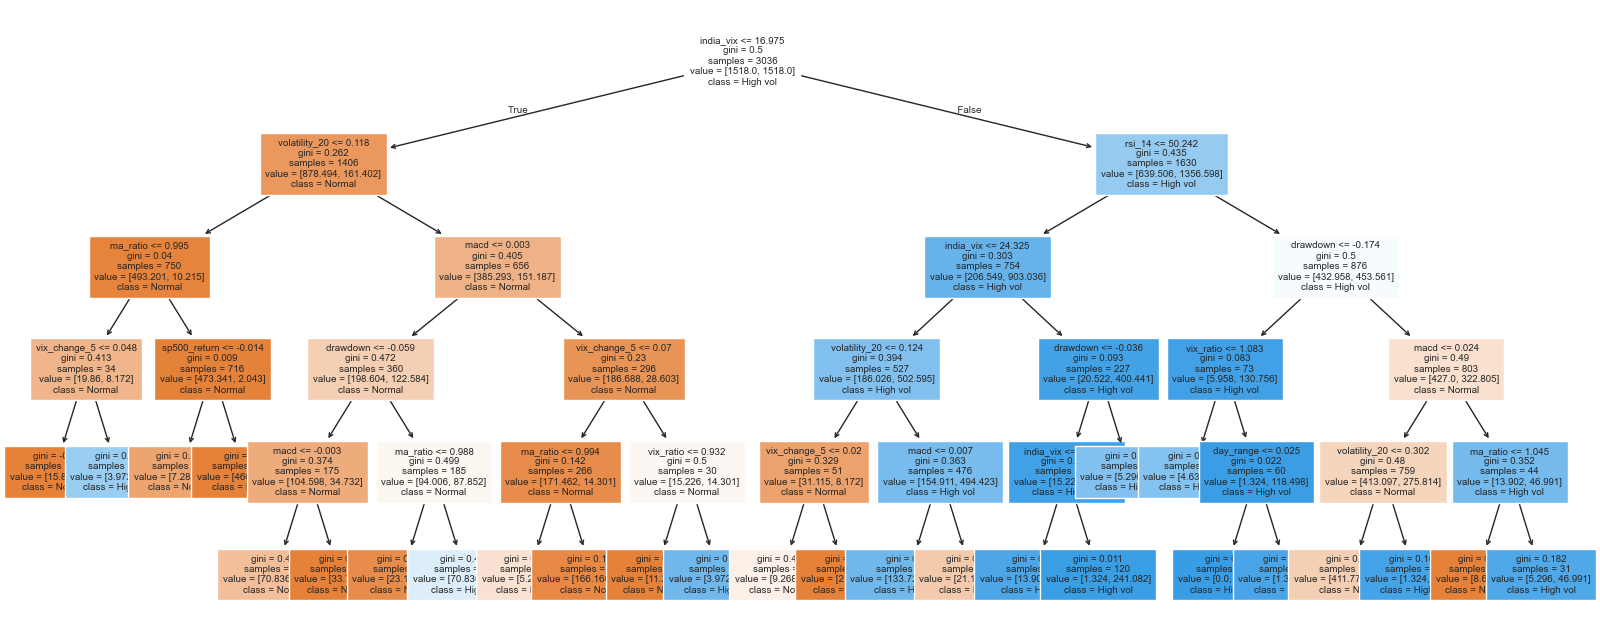

|--- india_vix <= 16.975
|   |--- volatility_20 <= 0.118
|   |   |--- ma_ratio <= 0.995
|   |   |   |--- vix_change_5 <= 0.048
|   |   |   |   |--- class: 0
|   |   |   |--- vix_change_5 >  0.048
|   |   |   |   |--- class: 1
|   |   |--- ma_ratio >  0.995
|   |   |   |--- sp500_return <= -0.014
|   |   |   |   |--- class: 0
|   |   |   |--- sp500_return >  -0.014
|   |   |   |   |--- class: 0
|   |--- volatility_20 >  0.118
|   |   |--- macd <= 0.003
|   |   |   |--- drawdown <= -0.059
|   |   |   |   |--- macd <= -0.003
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- macd >  -0.003
|   |   |   |   |   |--- class: 0
|   |   |   |--- drawdown >  -0.059
|   |   |   |   |--- ma_ratio <= 0.988
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- ma_ratio >  0.988
|   |   |   |   |   |--- class: 1
|   |   |--- macd >  0.003
|   |   |   |--- vix_change_5 <= 0.070
|   |   |   |   |--- ma_ratio <= 0.994
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- ma_ratio >  0.994
|   |   

In [24]:
plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=model_cols, class_names=['Normal', 'High vol'], filled=True, fontsize=7)
plt.show()

print(export_text(tree, feature_names=model_cols, decimals=3))

### KNN

A day is classified by majority vote of its k nearest training days.

$$d(x, x') = \sqrt{\sum (x_i - x'_i)^2}$$

In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils import resample

def oversample(Xa, ya, seed=42):
    # repeat high volatility days at random until both classes have the same count
    ya = np.asarray(ya)
    high_idx = np.where(ya == 1)[0]
    normal_idx = np.where(ya == 0)[0]
    extra = resample(high_idx, n_samples=len(normal_idx) - len(high_idx), random_state=seed)
    idx = np.concatenate([normal_idx, high_idx, extra])
    return Xa[idx], ya[idx]

X_bal, y_bal = oversample(X_train_s, y_train)
print('Before:', np.bincount(y_train), ' After oversampling:', np.bincount(y_bal))

knn = KNeighborsClassifier(n_neighbors=100)
knn.fit(X_bal, y_bal)
evaluate('KNN', knn, X_test_s)

Before: [2293  743]  After oversampling: [2293 2293]


KNN
Accuracy : 0.8622
Precision: 0.2823
Recall   : 0.407
F1       : 0.3333
AUC      : 0.6975
Log Loss : 0.6507


## 7. Neural Network (MLP)

Two hidden layers (32, 16), ReLU, Adam optimizer, early stopping.

`alpha=1.0` is the L2 penalty on the weights. It keeps the weights small, so the network overfits less.

MLP Neural Network
Accuracy : 0.8986
Precision: 0.3951
Recall   : 0.3721
F1       : 0.3832
AUC      : 0.7363
Log Loss : 0.2984


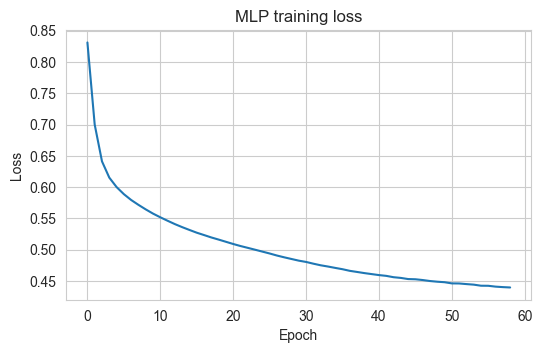

In [26]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', alpha=1.0,
                    early_stopping=True, max_iter=500, random_state=42)
mlp.fit(X_bal, y_bal)
evaluate('MLP Neural Network', mlp, X_test_s)

plt.figure(figsize=(6, 3.5))
plt.plot(mlp.loss_curve_)
plt.title('MLP training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## 8. Random Forest

Bagging: many trees on bootstrap samples, final answer by majority vote. (Boosting instead trains trees one after another on the previous mistakes.)

Random Forest
Accuracy : 0.8858
Precision: 0.337
Recall   : 0.3605
F1       : 0.3483
AUC      : 0.7599
Log Loss : 0.3315


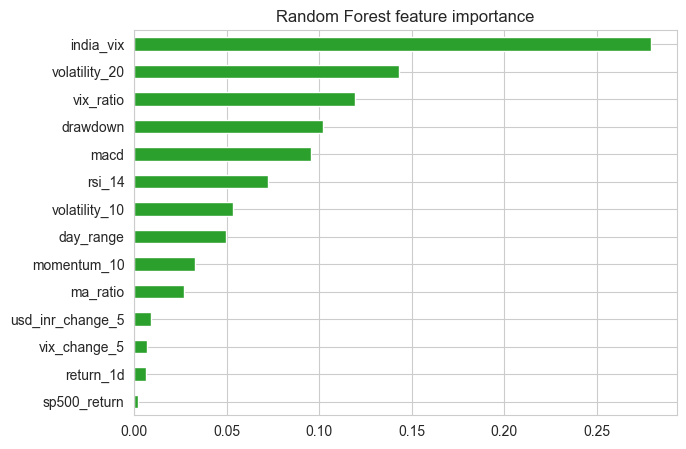

In [27]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=10,
                            class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
evaluate('Random Forest', rf, X_test)

pd.Series(rf.feature_importances_, index=model_cols).sort_values().plot(kind='barh', figsize=(7, 5), color='tab:green')
plt.title('Random Forest feature importance')
plt.show()

## 9. Model Comparison

In [28]:
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'Log Loss'])
results_df = results_df.set_index('Model')
print(results_df.round(4))

# two simple baselines to compare with
print()
print('Always predict "normal": accuracy =', round((y_test == 0).mean(), 4), ' F1 = 0')
print('Always predict "high"  : accuracy =', round((y_test == 1).mean(), 4),
      ' F1 =', round(f1_score(y_test, np.ones(len(y_test))), 4))

                     Accuracy  Precision  Recall      F1     AUC  Log Loss
Model                                                                     
Logistic Regression    0.8878     0.3600  0.4186  0.3871  0.7598    0.3625
Decision Tree          0.8287     0.2179  0.3953  0.2810  0.7505    1.0298
KNN                    0.8622     0.2823  0.4070  0.3333  0.6975    0.6507
MLP Neural Network     0.8986     0.3951  0.3721  0.3832  0.7363    0.2984
Random Forest          0.8858     0.3370  0.3605  0.3483  0.7599    0.3315

Always predict "normal": accuracy = 0.9154  F1 = 0
Always predict "high"  : accuracy = 0.0846  F1 = 0.1561


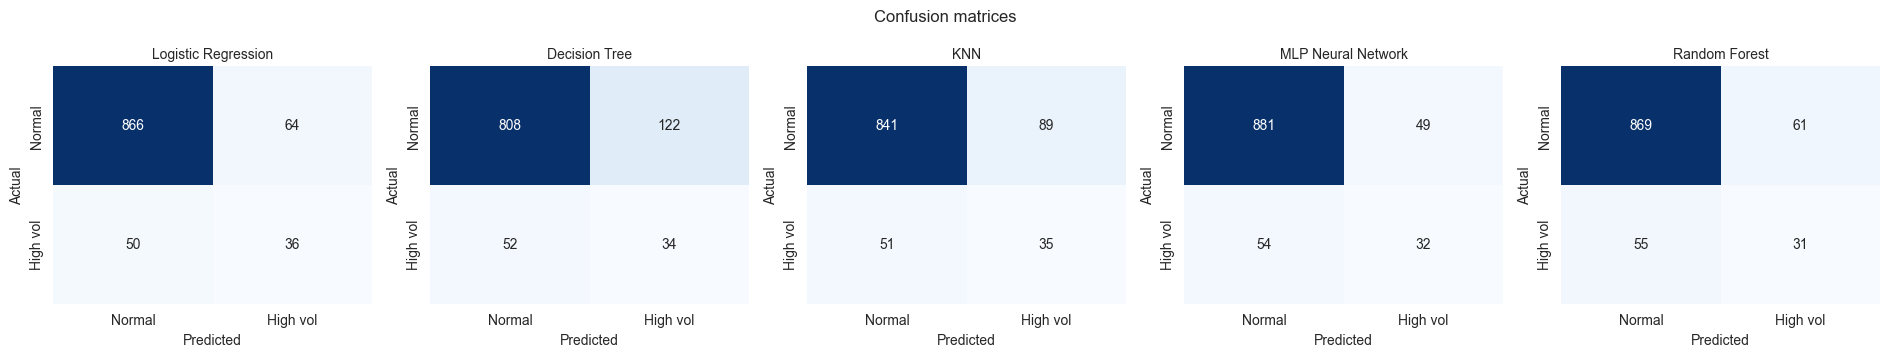

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
for ax, name in zip(axes, preds):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal', 'High vol'], yticklabels=['Normal', 'High vol'])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion matrices')
plt.tight_layout()
plt.show()

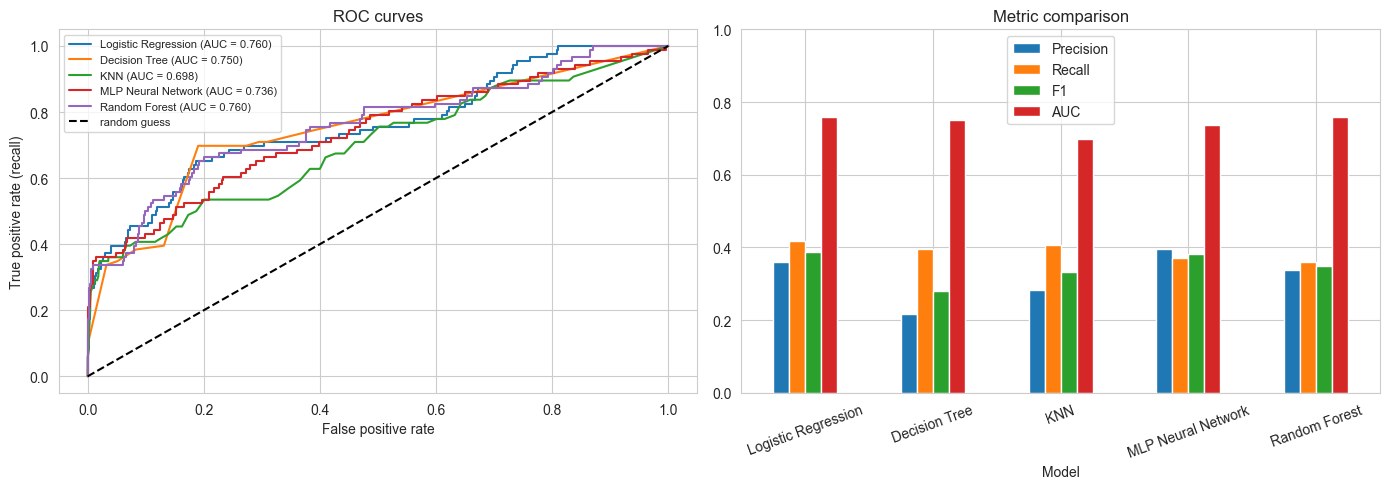

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in probs:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {results_df.loc[name, 'AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', label='random guess')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate (recall)')
axes[0].set_title('ROC curves')
axes[0].legend(fontsize=8)

results_df[['Precision', 'Recall', 'F1', 'AUC']].plot(kind='bar', ax=axes[1], rot=20)
axes[1].set_title('Metric comparison')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 10. Model Performance

### Bias-variance trade-off

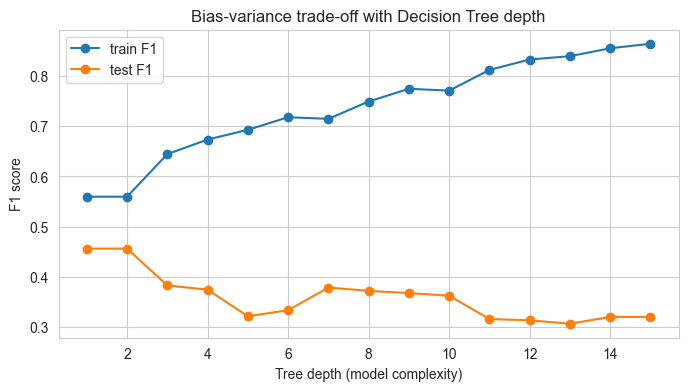

Best test depth: 1


In [31]:
depths = range(1, 16)
train_f1, test_f1 = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=5, class_weight='balanced', random_state=42)
    m.fit(X_train, y_train)
    train_f1.append(f1_score(y_train, m.predict(X_train)))
    test_f1.append(f1_score(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_f1, marker='o', label='train F1')
plt.plot(depths, test_f1, marker='o', label='test F1')
plt.xlabel('Tree depth (model complexity)')
plt.ylabel('F1 score')
plt.title('Bias-variance trade-off with Decision Tree depth')
plt.legend()
plt.show()
print('Best test depth:', depths[np.argmax(test_f1)])

### Time series cross-validation

In [32]:
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5, gap=horizon)
cv_rows = []
fold = 0
for tr, te in tscv.split(X):
    fold = fold + 1
    print('Fold', fold, ': test from', X.index[te[0]].date(), 'to', X.index[te[-1]].date())

    sc = StandardScaler()
    Xtr = sc.fit_transform(X.iloc[tr])
    Xte = sc.transform(X.iloc[te])
    ytr = y.iloc[tr].values
    yte = y.iloc[te].values

    for name in models:
        m = clone(models[name])   # same model and settings, but not trained yet
        if name == 'KNN' or name == 'MLP Neural Network':
            Xb, yb = oversample(Xtr, ytr)
            m.fit(Xb, yb)
        else:
            m.fit(Xtr, ytr)
        f1 = f1_score(yte, m.predict(Xte), zero_division=0)
        cv_rows.append([fold, name, f1])

cv_df = pd.DataFrame(cv_rows, columns=['Fold', 'Model', 'F1'])
cv_summary = cv_df.groupby('Model')['F1'].agg(['mean', 'std']).sort_values('mean', ascending=False)
cv_summary.round(4)

Fold 1 : test from 2013-01-08 to 2015-10-15


Fold 2 : test from 2015-10-16 to 2018-07-17


Fold 3 : test from 2018-07-18 to 2021-04-26


Fold 4 : test from 2021-04-27 to 2024-01-16


Fold 5 : test from 2024-01-17 to 2026-10-15


,mean,std
Model,,
Logistic Regression,0.5139,0.0744
Random Forest,0.5080,0.0907
KNN,0.4727,0.1082
MLP Neural Network,0.4719,0.0910
Decision Tree,0.4545,0.1533


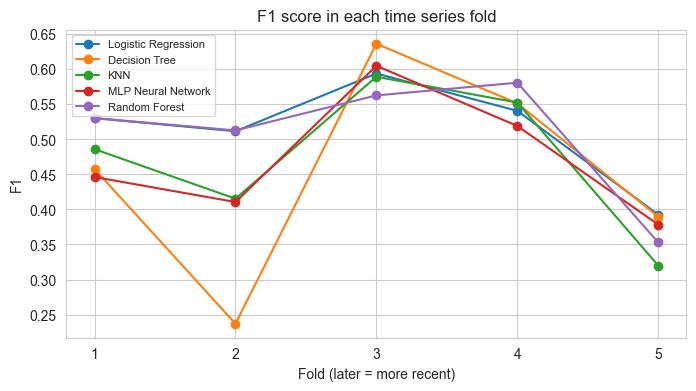

In [33]:
plt.figure(figsize=(8, 4))
for name in preds:
    part = cv_df[cv_df['Model'] == name]
    plt.plot(part['Fold'], part['F1'], marker='o', label=name)
plt.xlabel('Fold (later = more recent)')
plt.ylabel('F1')
plt.title('F1 score in each time series fold')
plt.xticks(range(1, 6))
plt.legend(fontsize=8)
plt.show()

## 11. PCA

Components needed for 90% variance: 8 (out of 14 features)


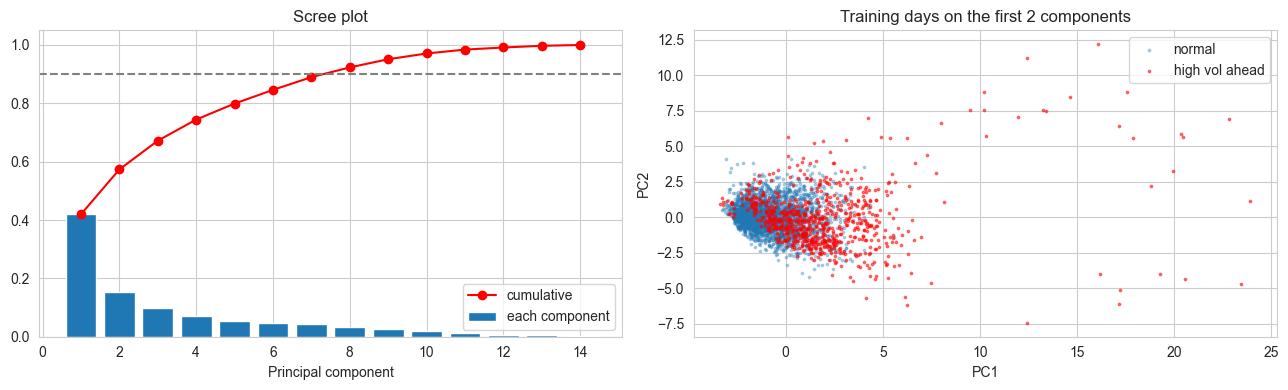

In [34]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.90) + 1)
print(f'Components needed for 90% variance: {n_comp} (out of {len(model_cols)} features)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_, label='each component')
axes[0].plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='red', label='cumulative')
axes[0].axhline(0.9, linestyle='--', color='grey')
axes[0].set_xlabel('Principal component')
axes[0].set_title('Scree plot')
axes[0].legend()

pc = PCA(n_components=2).fit(X_train_s).transform(X_train_s)
axes[1].scatter(pc[y_train.values == 0, 0], pc[y_train.values == 0, 1], s=3, alpha=0.3, label='normal')
axes[1].scatter(pc[y_train.values == 1, 0], pc[y_train.values == 1, 1], s=3, alpha=0.5, color='red', label='high vol ahead')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Training days on the first 2 components')
axes[1].legend()
plt.tight_layout()
plt.show()

In [35]:
pca = PCA(n_components=n_comp).fit(X_train_s)
lr_pca = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_pca.fit(pca.transform(X_train_s), y_train)
p = lr_pca.predict(pca.transform(X_test_s))

print('Logistic Regression with', len(model_cols), 'features: F1 =', round(results_df.loc['Logistic Regression', 'F1'], 4))
print('Logistic Regression with', n_comp, 'PCA components: F1 =', round(f1_score(y_test, p), 4))

pd.DataFrame(pca.components_[:2].T, index=model_cols, columns=['PC1', 'PC2']).round(3)

Logistic Regression with 14 features: F1 = 0.3871
Logistic Regression with 8 PCA components: F1 = 0.3545


,PC1,PC2
return_1d,-0.066,0.360
momentum_10,-0.223,0.475
volatility_10,0.353,0.232
volatility_20,0.336,0.320
ma_ratio,-0.284,-0.164
day_range,0.280,-0.035
drawdown,-0.329,-0.061
rsi_14,-0.230,0.393
macd,-0.351,0.078
sp500_return,-0.023,0.254


## 12. Clustering

### K-Means

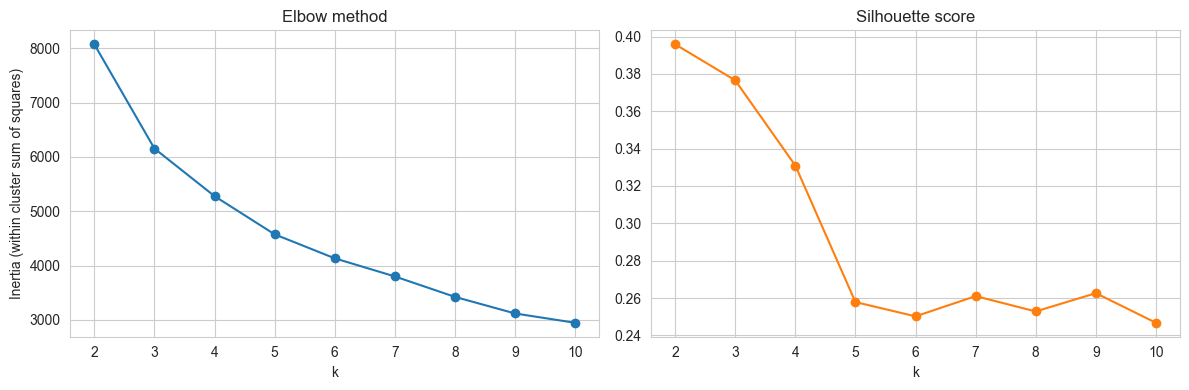

In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

regime_features = ['momentum_10', 'volatility_20', 'ma_ratio', 'drawdown']
reg_scaler = StandardScaler().fit(X_train[regime_features])
Z_train = reg_scaler.transform(X_train[regime_features])
Z_all = reg_scaler.transform(X[regime_features])

ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_train)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z_train, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, marker='o')
axes[0].set_title('Elbow method')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia (within cluster sum of squares)')
axes[1].plot(ks, sil, marker='o', color='tab:orange')
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()

Random initialization trap:

In [37]:
random_runs = [KMeans(n_clusters=4, init='random', n_init=1, random_state=s).fit(Z_train).inertia_ for s in range(10)]
plus_runs = [KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=s).fit(Z_train).inertia_ for s in range(10)]
print('Random init, 1 start : min %.1f  max %.1f' % (min(random_runs), max(random_runs)))
print('k-means++, 10 starts : min %.1f  max %.1f' % (min(plus_runs), max(plus_runs)))

Random init, 1 start : min 5279.0  max 6178.5
k-means++, 10 starts : min 5278.9  max 5279.5


In [38]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z_train)
df_clean['cluster'] = kmeans.predict(Z_all)

# cluster centres in the original units
centres = pd.DataFrame(reg_scaler.inverse_transform(kmeans.cluster_centers_), columns=regime_features)

# give each cluster a name by looking at its centre
hv = centres['volatility_20'].idxmax()      # most volatile cluster
others = centres.drop(hv)
bull = others['ma_ratio'].idxmax()          # strongest up trend
bear = others['ma_ratio'].idxmin()          # strongest down trend
names = {}
for c in centres.index:
    names[c] = 'Sideways'
names[hv] = 'High Volatility'
names[bull] = 'Bull'
names[bear] = 'Bear'
df_clean['kmeans_regime'] = df_clean['cluster'].map(names)

centres.index = [names[i] for i in centres.index]
print(centres.round(4))
print()
km_table = pd.DataFrame({
    'Days': df_clean['kmeans_regime'].value_counts().reindex(regime_order),
    'High vol %': (df_clean.groupby('kmeans_regime')['target'].mean() * 100).reindex(regime_order).round(1)
})
print(km_table)
same = (df_clean['kmeans_regime'] == df_clean['regime']).mean() * 100
print('\nSame regime as the rule based method on', round(same, 1), '% of days')

                 momentum_10  volatility_20  ma_ratio  drawdown
Bull                  0.0164         0.1252    1.0194   -0.0251
Sideways             -0.0355         0.1681    0.9989   -0.0978
High Volatility      -0.0305         0.6743    0.8798   -0.2823
Bear                  0.0181         0.2120    0.9782   -0.1225

                 Days  High vol %
kmeans_regime                    
Bull             2461        10.2
Sideways          934        35.9
Bear              633        33.3
High Volatility    34       100.0

Same regime as the rule based method on 50.6 % of days


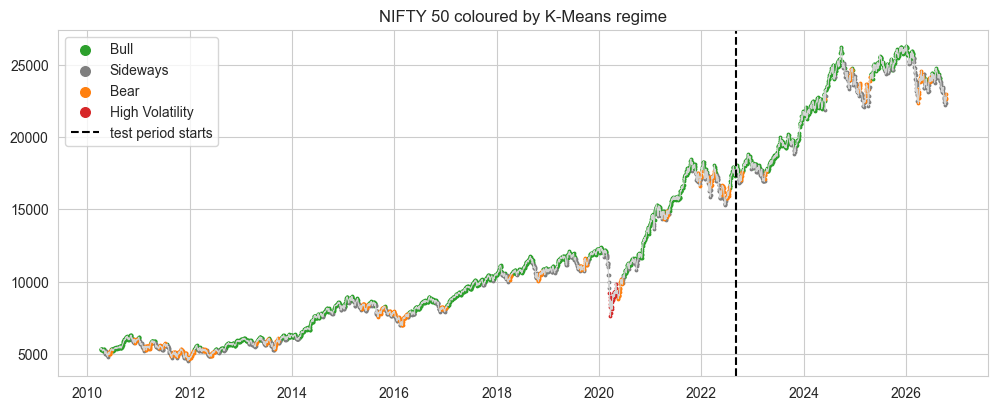

In [39]:
colours = {'Bull': 'tab:green', 'Sideways': 'tab:grey', 'Bear': 'tab:orange', 'High Volatility': 'tab:red'}
plt.figure(figsize=(12, 4.5))
plt.plot(df_clean.index, df_clean['Close'], color='lightgrey', linewidth=0.8)
for r in regime_order:
    part = df_clean[df_clean['kmeans_regime'] == r]
    plt.scatter(part.index, part['Close'], s=3, color=colours[r], label=r)
plt.axvline(X_test.index.min(), color='black', linestyle='--', label='test period starts')
plt.title('NIFTY 50 coloured by K-Means regime')
plt.legend(markerscale=4)
plt.show()

### Gaussian Mixture Model (GMM)

Like K-Means, but each cluster is a Gaussian and every day gets a probability of belonging to each regime (soft clustering). Number of components chosen with BIC.

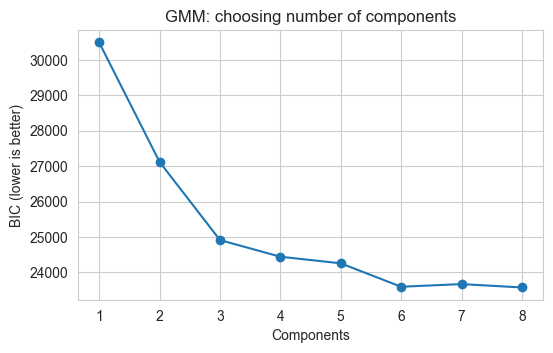

,Days,High vol %
gmm_regime,,
Bull,1492,7.6
Sideways,427,53.4
Bear,2107,21.5
High Volatility,36,100.0


In [40]:
from sklearn.mixture import GaussianMixture

comps = range(1, 9)
bic = [GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(Z_train).bic(Z_train) for k in comps]
plt.figure(figsize=(6, 3.5))
plt.plot(comps, bic, marker='o')
plt.xlabel('Components')
plt.ylabel('BIC (lower is better)')
plt.title('GMM: choosing number of components')
plt.show()

gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42).fit(Z_train)
gmm_means = pd.DataFrame(reg_scaler.inverse_transform(gmm.means_), columns=regime_features)
# name the components the same way as the K-Means clusters
hv = gmm_means['volatility_20'].idxmax()
others = gmm_means.drop(hv)
g_names = {}
for c in gmm_means.index:
    g_names[c] = 'Sideways'
g_names[hv] = 'High Volatility'
g_names[others['ma_ratio'].idxmax()] = 'Bull'
g_names[others['ma_ratio'].idxmin()] = 'Bear'
df_clean['gmm_regime'] = pd.Series(gmm.predict(Z_all), index=df_clean.index).map(g_names)

# probability of being in the High Volatility component
df_clean['p_high_vol'] = gmm.predict_proba(Z_all)[:, hv]

pd.DataFrame({
    'Days': df_clean['gmm_regime'].value_counts().reindex(regime_order),
    'High vol %': (df_clean.groupby('gmm_regime')['target'].mean() * 100).reindex(regime_order).round(1)
})

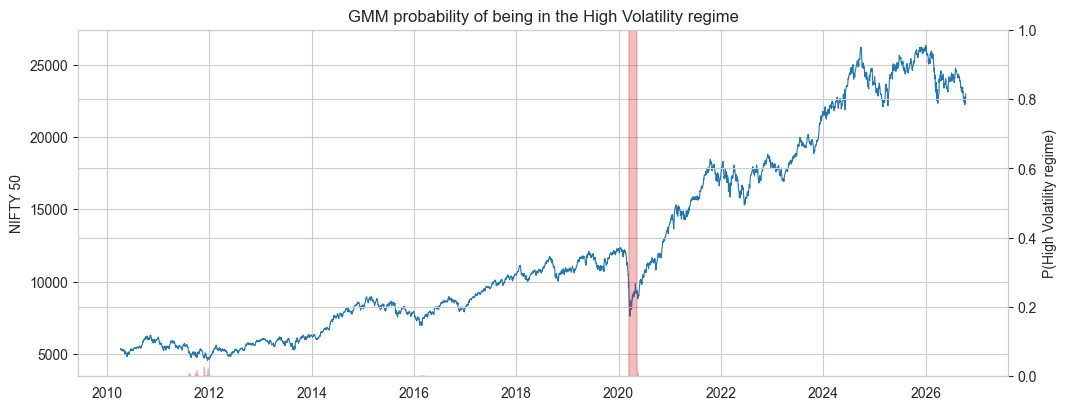

,count,mean
p_high_vol,,
"(-0.001, 0.2]",4026,0.197
"(0.8, 1.0]",36,1.000


In [41]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(df_clean.index, df_clean['Close'], color='tab:blue', linewidth=0.8)
ax1.set_ylabel('NIFTY 50')
ax2 = ax1.twinx()
ax2.fill_between(df_clean.index, df_clean['p_high_vol'], color='tab:red', alpha=0.3)
ax2.set_ylabel('P(High Volatility regime)')
ax2.set_ylim(0, 1)
plt.title('GMM probability of being in the High Volatility regime')
plt.show()

df_clean.groupby(pd.cut(df_clean['p_high_vol'], [0, 0.2, 0.5, 0.8, 1.0], include_lowest=True))['target'].agg(['count', 'mean']).round(3)

### Hierarchical Clustering

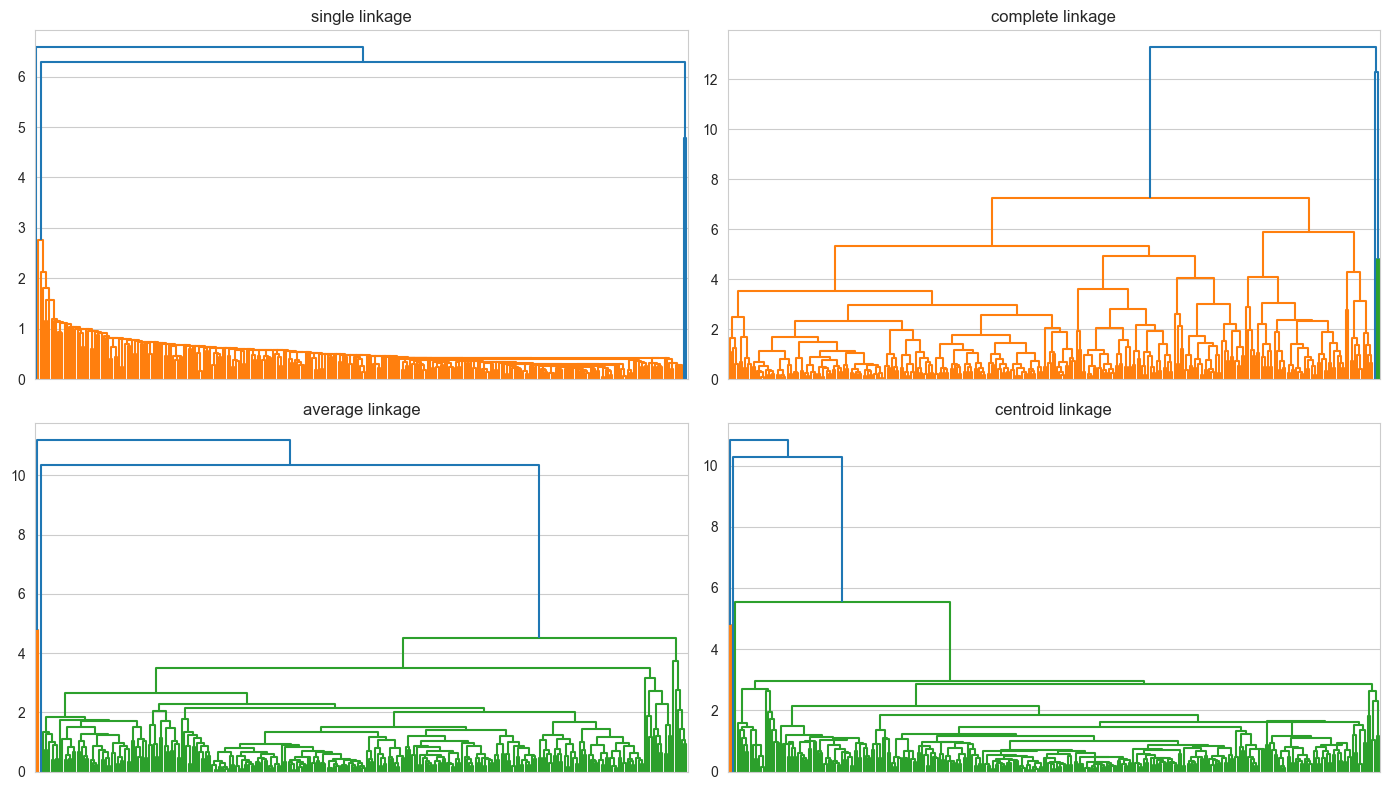

,Linkage,Cluster sizes,Silhouette
0,single,"[297, 1, 1, 1]",0.765
1,complete,"[238, 59, 2, 1]",0.366
2,average,"[297, 1, 1, 1]",0.765
3,centroid,"[296, 2, 1, 1]",0.584


In [42]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sample_idx = np.linspace(0, len(Z_train) - 1, 300).astype(int)
Z_sample = Z_train[sample_idx]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
hc_rows = []
for ax, method in zip(axes.flat, ['single', 'complete', 'average', 'centroid']):
    L = linkage(Z_sample, method=method)
    dendrogram(L, ax=ax, no_labels=True, color_threshold=None)
    ax.set_title(f'{method} linkage')
    labels = fcluster(L, t=4, criterion='maxclust')
    sizes = np.bincount(labels)[1:]
    score = silhouette_score(Z_sample, labels)
    hc_rows.append([method, sorted(sizes, reverse=True), round(score, 3)])
plt.tight_layout()
plt.show()

pd.DataFrame(hc_rows, columns=['Linkage', 'Cluster sizes', 'Silhouette'])

## 13. Association Rules

Each day is a transaction, market conditions are the items. Rules of the form {conditions} -> High vol ahead.

Lift = confidence / P(high vol ahead). Training data only.

In [43]:
train_days = df_clean.loc[X_train.index]

items = pd.DataFrame(index=train_days.index)
items['High volatility'] = train_days['volatility_20'] > train_days['volatility_20'].quantile(0.8)
items['Below 50 day avg'] = train_days['ma_ratio'] < 1
items['Drawdown > 5%'] = train_days['drawdown'] < -0.05
items['RSI < 40'] = train_days['rsi_14'] < 40
items['RSI > 70'] = train_days['rsi_14'] > 70
items['Fell > 1% today'] = train_days['return_1d'] < -0.01
items['Big daily range'] = train_days['day_range'] > train_days['day_range'].quantile(0.8)
items['US fell > 1%'] = train_days['sp500_return'] < -0.01
items['VIX high'] = train_days['india_vix'] > train_days['india_vix'].quantile(0.8)
items['VIX rising'] = train_days['vix_change_5'] > 0.10
items['Crude jumped > 2%'] = train_days['crude_return'] > 0.02

vol_ahead = train_days['target'] == 1
base_rate = vol_ahead.mean()
print('Number of items:', items.shape[1])
print('P(high vol ahead) in training data:', round(base_rate, 3))
items.mean().sort_values(ascending=False).round(3).to_frame('Support')

Number of items: 11
P(high vol ahead) in training data: 0.245


,Support
Drawdown > 5%,0.466
Below 50 day avg,0.345
RSI < 40,0.207
RSI > 70,0.206
High volatility,0.200
Big daily range,0.200
VIX high,0.199
VIX rising,0.162
Crude jumped > 2%,0.147
Fell > 1% today,0.126


In [44]:
min_support = 0.02
rules = []
for size in [1, 2]:
    for combo in combinations(items.columns, size):
        has_all = items[list(combo)].all(axis=1)
        sup_a = has_all.mean()
        if sup_a < min_support:
            continue
        sup_rule = (has_all & vol_ahead).mean()
        conf = sup_rule / sup_a
        lift = conf / base_rate
        rules.append([' + '.join(combo), 'High vol ahead', sup_rule, conf, lift, has_all.sum()])

rules_df = pd.DataFrame(rules, columns=['If', 'Then', 'Support', 'Confidence', 'Lift', 'Days'])
rules_df = rules_df.sort_values('Lift', ascending=False).reset_index(drop=True)
print('Rules found:', len(rules_df))
rules_df.head(10).round(3)

Rules found: 59


,If,Then,Support,Confidence,Lift,Days
0,High volatility + RSI < 40,High vol ahead,0.044,0.881,3.599,151
1,RSI < 40 + VIX high,High vol ahead,0.054,0.832,3.398,196
2,High volatility + VIX rising,High vol ahead,0.029,0.750,3.065,116
3,Fell > 1% today + VIX high,High vol ahead,0.036,0.714,2.919,154
4,RSI < 40 + Big daily range,High vol ahead,0.057,0.710,2.902,245
5,Below 50 day avg + VIX high,High vol ahead,0.080,0.710,2.900,341
6,VIX high + Crude jumped > 2%,High vol ahead,0.026,0.690,2.818,116
7,Big daily range + VIX high,High vol ahead,0.070,0.688,2.812,311
8,US fell > 1% + VIX high,High vol ahead,0.028,0.688,2.811,125
9,High volatility + Fell > 1% today,High vol ahead,0.030,0.687,2.807,131


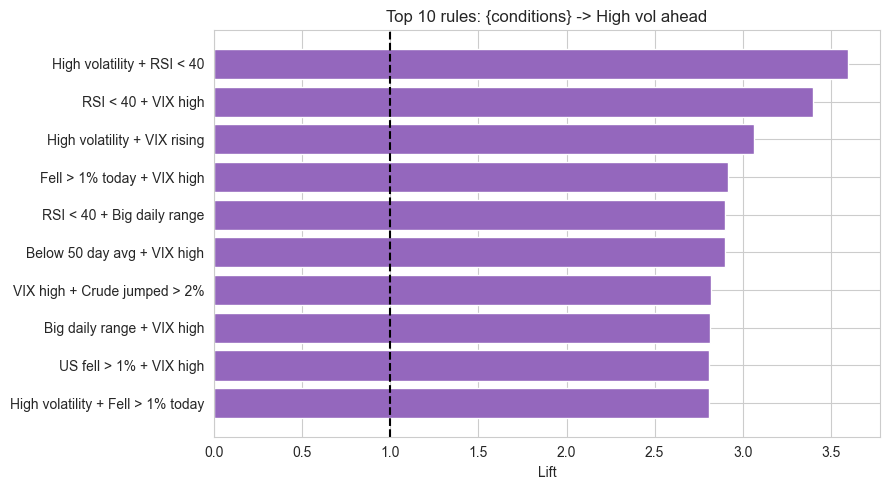

In [45]:
top = rules_df.head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top['If'], top['Lift'], color='tab:purple')
plt.axvline(1, color='black', linestyle='--')
plt.xlabel('Lift')
plt.title('Top 10 rules: {conditions} -> High vol ahead')
plt.tight_layout()
plt.show()

## 14. Best Model and Conclusion

In [46]:
best_test = results_df['F1'].idxmax()
best_auc = results_df['AUC'].idxmax()
best_cv = cv_summary['mean'].idxmax()

print('Best model by test F1 :', best_test)
print(results_df.loc[best_test].round(4))
print()
print('Best model by test AUC:', best_auc)
print('Best model by CV F1   :', best_cv, '(mean', round(cv_summary.loc[best_cv, 'mean'], 4),
      ', std', round(cv_summary.loc[best_cv, 'std'], 4), ')')

Best model by test F1 : Logistic Regression
Accuracy     0.8878
Precision    0.3600
Recall       0.4186
F1           0.3871
AUC          0.7598
Log Loss     0.3625
Name: Logistic Regression, dtype: float64

Best model by test AUC: Random Forest
Best model by CV F1   : Logistic Regression (mean 0.5139 , std 0.0744 )


**Conclusion**

- Best model: ___
- PCA components for 90% variance: ___
- High volatility rate in the High Volatility regime: ___%
- Top association rule: ___ (lift ___)

Limitation: volatility is predictable because it clusters, but sudden shocks (news, policy, global events) that start a volatile period from a calm market are still hard to see in advance.